# ECSE-4840 HW4
### Grace Yu, RIN: 662056533

## Question 1, Part A

See the source code below. 

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time
import sklearn
from torch.utils.data import TensorDataset, DataLoader

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load KMNIST dataset
X_train = np.load("kmnist-train-imgs.npz")["arr_0"]
y_train = np.load("kmnist-train-labels.npz")["arr_0"]

X_test = np.load("kmnist-test-imgs.npz")["arr_0"]
y_test = np.load("kmnist-test-labels.npz")["arr_0"]

X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1) / 255.0
y_train = torch.tensor(y_train, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1) / 255.0
y_test = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

In [14]:
def softmax(x):
    x = x - torch.max(x, dim=1, keepdim=True).values
    exp_x = torch.exp(x)
    return exp_x / torch.sum(exp_x, dim=1, keepdim=True)

class MLP(nn.Module):
    def __init__(self, hidden_size=64):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return softmax(x)

def cross_entropy_loss(probabilities, labels):
    selected = probabilities[torch.arange(len(labels), device=labels.device), labels]
    return -torch.log(selected.clamp(min=1e-12)).mean()

def train_model(model, train_loader, epochs=3, lr=0.01):
    model = model.to(device)
    criterion = cross_entropy_loss
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_history = []
    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for x, y in train_loader:

            x = x.to(device)
            y = y.to(device)
            # Forward propagation
            outputs = model(x)
            loss = criterion(outputs, y)
            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)
        loss_history.append(epoch_loss)

        print(f"Epoch {epoch+1}/{epochs}: Loss = {epoch_loss:.4f}")
    training_time = time.perf_counter() - start_time
    print(f"Training time: {training_time:.2f} seconds")
    return model, loss_history, training_time

def evaluate_model(model, data_loader):
    model.eval()
    y_true = []
    y_pred = []
    start_time = time.perf_counter()
    with torch.no_grad():
        for x, y in data_loader:
            x = x.to(device)
            outputs = model(x)
            predictions = torch.argmax(outputs, dim=1)
            y_true.extend(y.numpy())
            y_pred.extend(predictions.cpu().numpy())
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    accuracy = np.mean(y_true == y_pred)
    testing_time = time.perf_counter() - start_time
    return accuracy, y_true, y_pred, testing_time

Epoch 1/3: Loss = 0.3942
Epoch 2/3: Loss = 0.2308
Epoch 3/3: Loss = 0.1914
Training time: 4.65 seconds

Training accuracy: 95.55%
Testing accuracy: 85.12%
Testing time: 0.09 seconds


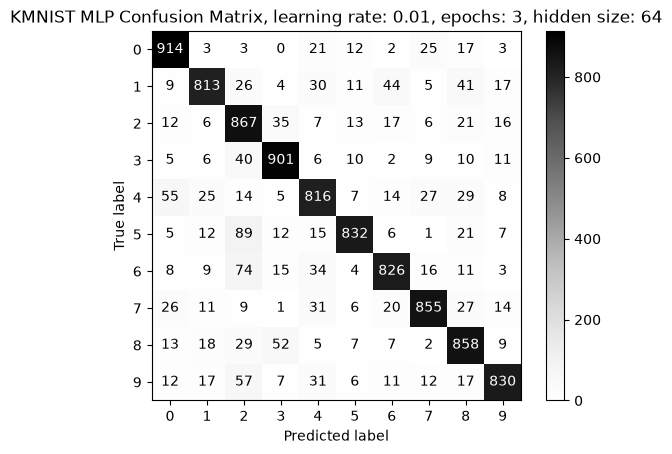

In [21]:
torch.manual_seed(1)

model = MLP(hidden_size=64)

# Train model
model, loss_history, training_time = train_model(model, train_loader, epochs=3, lr=0.01)

# Evaluate training accuracy
train_accuracy, train_true, train_pred, training_time = evaluate_model(model, train_loader)

# Evaluate testing accuracy

test_accuracy, test_true, test_pred, testing_time = evaluate_model(model, test_loader)

print(f"\nTraining accuracy: {train_accuracy*100:.2f}%")
print(f"Testing accuracy: {test_accuracy*100:.2f}%")
print(f"Testing time: {testing_time:.2f} seconds")

cm = sklearn.metrics.confusion_matrix(test_true, test_pred)
disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Greys")
plt.title("KMNIST MLP Confusion Matrix, learning rate: 0.01, epochs: 3, hidden size: 64")
plt.show()

The solution to Part A is shown at the end of the code block above. 

During training, it seems like with each epoch, training losses decreases. The reported training accuracy is 95.55% and the testing accuracy is only 85.12%, over 10% lower than the training data. This indicates overfitting as the model when used on the testing data is performing significantly worse than it while using the training data.

## Question 1 Part B - Hyperparameter tuning

Results (using the same seed for consistency): 

When starting from the default parameters from part A, here are the general trends

Increasing the number of hidden elements - decreases training losses and improves training and testing accuracies. Depending on the value of hidden elements, the difference between training and testing accuracies fluctuated around 10%
- ex. when hidden elements = 100, learning rate = 0.01, epoch = 3, the resultant training loss went down to 0.1698, training accuracy went up to 96% while testing accuracy improved to 87.07%, almost 2% better than with 64 hidden elements. Improvements seem to reach a plateau past 150+ hidden elements

Increasing the number of trainng epochs reduces the training loss but increases the discrepancy between training and testing accuracies, indicating overfitting. Testing accuracy did not improve significantly.
- ex. when hidden elements = 64, learning rate = 0.01, epoch = 5, the resultant training loss goes down to 0.1551, versus 0.1914 after epoch 3. The difference between training and testing accuracies went from 10.43% (epoch = 3) to 10.87%. Training accuracy went up by over almost 1% while testing accuracy only improved by 0.32%

Decreasing the number of training epochs down to 2 did not cause a decrease the testing accuracy significantly, but training accuracy went down by 1% and training losses ended up at 0.2302

A more coarse learning rate (such as 0.02) reduced the training and testing accuracy significantly, but a smaller learning rate also did not seem to improve accuracies - lower than 0.005 led to a decrease in training and testing accuracy. 0.01 seems like a sweet point without changing the epochs. But it does help improve general model performance. When reducing learning rate and increasing the number of epochs concurrently, the model performance improved significantly.

The code block below shows the best performing hyperparameters (learning rate: 0.001, epochs: 14, hidden size: 196) results. The training accuracy went up to 99.86% while testing accuracy improved to 90.39%, though the discrepancy between them is still almost 10%, indicating that overtraining is likely - but reducing the number of epochs also decreases testing accuracy.

Epoch 1/14: Loss = 0.5420
Epoch 2/14: Loss = 0.2721
Epoch 3/14: Loss = 0.1966
Epoch 4/14: Loss = 0.1508
Epoch 5/14: Loss = 0.1186
Epoch 6/14: Loss = 0.0970
Epoch 7/14: Loss = 0.0771
Epoch 8/14: Loss = 0.0624
Epoch 9/14: Loss = 0.0489
Epoch 10/14: Loss = 0.0403
Epoch 11/14: Loss = 0.0318
Epoch 12/14: Loss = 0.0254
Epoch 13/14: Loss = 0.0199
Epoch 14/14: Loss = 0.0158
Training time: 21.90 seconds

Training accuracy: 99.86%
Testing accuracy: 90.39%
Testing time: 0.09 seconds


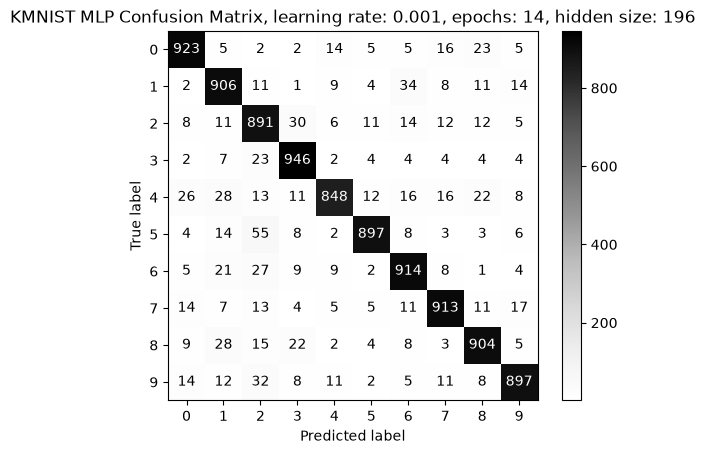

In [22]:
torch.manual_seed(1)

model = MLP(hidden_size=196)

# Train model
model, loss_history, training_time = train_model(model, train_loader, epochs=14, lr=0.001)

# Evaluate training accuracy
train_accuracy, train_true, train_pred, training_time = evaluate_model(model, train_loader)

# Evaluate testing accuracy
test_accuracy, test_true, test_pred, testing_time = evaluate_model(model, test_loader)

print(f"\nTraining accuracy: {train_accuracy*100:.2f}%")
print(f"Testing accuracy: {test_accuracy*100:.2f}%")
print(f"Testing time: {testing_time:.2f} seconds")

cm = sklearn.metrics.confusion_matrix(test_true, test_pred)
disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Greys")
plt.title("KMNIST MLP Confusion Matrix, learning rate: 0.001, epochs: 14, hidden size: 196")
plt.show()

## Question 1 Part C: multi-layer CNN

The CNN definition source code is shown below

In [23]:
class CNN(nn.Module):
    def __init__(self, channels=(8, 16, 32), batch_norm=True):
        super().__init__()

        layers = []
        in_channels = 1
        image_size = 28

        for out_channels in channels:
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))

            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))

            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))

            in_channels = out_channels
            image_size = image_size // 2

        self.features = nn.Sequential(*layers)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(in_channels * image_size * image_size, 10)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.fc(x)

        return softmax(x)

Starting with the default number of channels, keeping learning rate and number of epochs the same as the optimal for the MLP

Epoch 1/14: Loss = 0.4780
Epoch 2/14: Loss = 0.1563
Epoch 3/14: Loss = 0.1097
Epoch 4/14: Loss = 0.0865
Epoch 5/14: Loss = 0.0723
Epoch 6/14: Loss = 0.0609
Epoch 7/14: Loss = 0.0550
Epoch 8/14: Loss = 0.0493
Epoch 9/14: Loss = 0.0429
Epoch 10/14: Loss = 0.0391
Epoch 11/14: Loss = 0.0345
Epoch 12/14: Loss = 0.0312
Epoch 13/14: Loss = 0.0293
Epoch 14/14: Loss = 0.0256
Training time: 35.77 seconds

Training accuracy: 99.44%
Testing accuracy: 93.62%
Testing time: 0.16 seconds


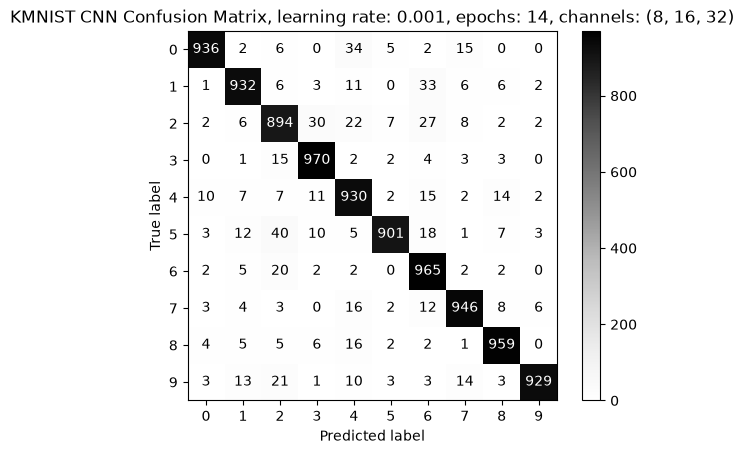

In [24]:
torch.manual_seed(1)

model = CNN(channels=(8, 16, 32), batch_norm=True)

# Train model
model, loss_history, training_time = train_model(model, train_loader, epochs=14, lr=0.001)

# Evaluate training accuracy
train_accuracy, train_true, train_pred, training_time = evaluate_model(model, train_loader)

# Evaluate testing accuracy
test_accuracy, test_true, test_pred, testing_time = evaluate_model(model, test_loader)

print(f"\nTraining accuracy: {train_accuracy*100:.2f}%")
print(f"Testing accuracy: {test_accuracy*100:.2f}%")
print(f"Testing time: {testing_time:.2f} seconds")

cm = sklearn.metrics.confusion_matrix(test_true, test_pred)
disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Greys")
plt.title("KMNIST CNN Confusion Matrix, learning rate: 0.001, epochs: 14, channels: (8, 16, 32)")
plt.show()

Trying some other parameters:

Without changing the number of epochs and the learning rate, increasing the number of channels improved testing accuracy - training accuracy, using epoch = 14 and learning rate = 0.001 was already almost 100%. But the model does eventually plateau out when the max. number of channels reach 256. 

Changing the channel parameters into a palindrome where $(n, m, n), m = 2n$ decreased testing accuracy, in comparison to $(\frac{m}{2}, m, 2m)$. But for $(n, m, n)$ where $n=2m$, testing accuracy improved. Once again, training accuracy in each case remained very close to 100%.

Increasing the ratio between $n$ and $m$ also helped improving training accuracy ever so slightly, although $m = 2n$ seems like the best balance between reasonably short training time and high testing accuracy.

Changing the batch norm to false reduces the run time significantly but also decreases testing accuracy by ~0.2%. 

At epoch = 14, keeping the same learning rate, it seems like there may be some over training as training losses approach the minima as after epoch 7 in the example below:channels = (128, 64, 128)

*Epoch 1/14: Loss = 0.2185*

*Epoch 2/14: Loss = 0.0650*

*Epoch 3/14: Loss = 0.0403*

*Epoch 4/14: Loss = 0.0253*

*Epoch 5/14: Loss = 0.0200*

*Epoch 6/14: Loss = 0.0153*

*Epoch 7/14: Loss = 0.0082*

*Epoch 8/14: Loss = 0.0059*

*Epoch 9/14: Loss = 0.0072*

*Epoch 10/14: Loss = 0.0120*

*Epoch 11/14: Loss = 0.0045*

*Epoch 12/14: Loss = 0.0036*

*Epoch 13/14: Loss = 0.0095*

*Epoch 14/14: Loss = 0.0096*


Using a smaller learning rate at the same number of epoches did not improve the testing accuracy, while reducing the number of epoches reduced training time without reducing testing accuracy significantly. 

After playing around with the model, the best performing hyperparameters (channels = (128, 64, 128), epochs = 12, learning rate = 0.001) yielded a training accuracy of 100% and a testing accuracy of 96.57%, over a total training time of 58.06s. This is significantly longer than the single layer MLP, where with its best performing parameters, yielded a 21.90s training time, albeit with a significantly lower testing accuracy

The full results are shown below. 

Epoch 1/12: Loss = 0.2183
Epoch 2/12: Loss = 0.0643
Epoch 3/12: Loss = 0.0408
Epoch 4/12: Loss = 0.0258
Epoch 5/12: Loss = 0.0189
Epoch 6/12: Loss = 0.0127
Epoch 7/12: Loss = 0.0080
Epoch 8/12: Loss = 0.0087
Epoch 9/12: Loss = 0.0087
Epoch 10/12: Loss = 0.0108
Epoch 11/12: Loss = 0.0049
Epoch 12/12: Loss = 0.0011
Training time: 58.06 seconds

Training accuracy: 100.00%
Testing accuracy: 96.57%
Testing time: 0.30 seconds


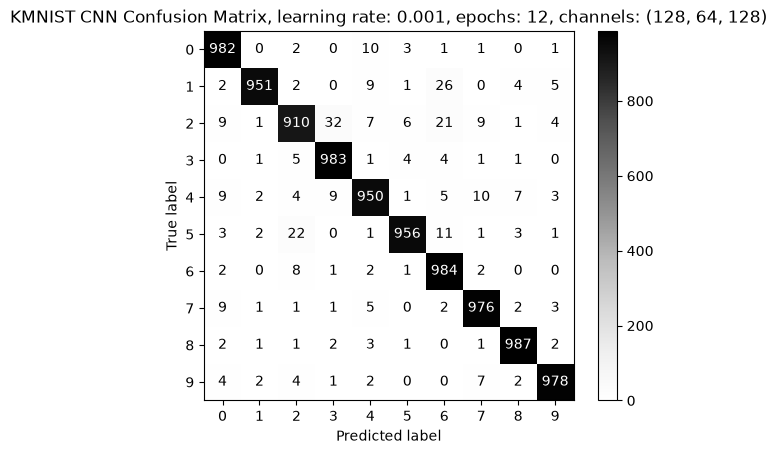

In [33]:
torch.manual_seed(1)

model = CNN(channels=(128, 64, 128), batch_norm=True)

# Train model
model, loss_history, training_time = train_model(model, train_loader, epochs=12, lr=0.001)

# Evaluate training accuracy
train_accuracy, train_true, train_pred, training_time = evaluate_model(model, train_loader)

# Evaluate testing accuracy
test_accuracy, test_true, test_pred, testing_time = evaluate_model(model, test_loader)

print(f"\nTraining accuracy: {train_accuracy*100:.2f}%")
print(f"Testing accuracy: {test_accuracy*100:.2f}%")
print(f"Testing time: {testing_time:.2f} seconds")

cm = sklearn.metrics.confusion_matrix(test_true, test_pred)
disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Greys")
plt.title("KMNIST CNN Confusion Matrix, learning rate: 0.001, epochs: 12, channels: (128, 64, 128)")
plt.show()

## Question 2 - KNN

The testing accuracy is 91.49%, which a lower than the multilayer CNN but slightly higher than the single layer MLP. 

KNN's main benefit is that it is extremely fast to train, as training took only 0.02s for the KNN, versus ~20s for the optimal MLP and over a minute for the optimal CNN. However, it does take significantly longer to make predictions. Another one of its benefits is that it is also non-parametric - it has only a few hyperparameters, versus for CNN and MLP, training accuracy highly depends on the layer structures. Lastly, if data is frequently added into the system, KNN would be highly advantageous as retraining the model is extremely fast.

However, its disadvantages include - has high computational costs during inference, can struggle (especially when compared to MLP and CNN) when the dimensionality of the feature space gets large or has feature scaling issues. Also, it requires the training dataset during classification, which can create a memory or runtime problem. 

KNN/MLP/CNN model performance comparison:

|     Model     | Training accuracy | Testing accuracy | Training time | Classification time |
|:-------------:|:-----------------:|:----------------:|:-------------:|:-------------------:|
| MLP           | 95.55%            | 85.12%           | 4.65s         | 0.09s               |
| Optimized MLP | 99.86%            | 90.39%           | 21.90s        | 0.09s               |
| CNN           | 100%              | 96.57%           | 58.06s        | 0.30s               |
| kNN (k=4)     | 97.90%            | 91.49%           | 0.03s         | 6.61s               |

See the source code below.

In [34]:
def knn_predict_random_tie(knn, X, y_train, seed=1):
    rng = np.random.default_rng(seed)

    neighbor_indices = knn.kneighbors(X, return_distance=False)
    neighbor_labels = y_train[neighbor_indices]

    predictions = []

    for labels in neighbor_labels:
        counts = np.bincount(labels, minlength=10)

        max_count = np.max(counts)
        tied_classes = np.where(counts == max_count)[0]

        predictions.append(rng.choice(tied_classes))

    return np.array(predictions)

# Reshaping dataset
X_train_knn = X_train.reshape(len(X_train), -1).cpu().numpy()
X_test_knn = X_test.reshape(len(X_test), -1).cpu().numpy()

# Initialize and train
knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=4, n_jobs=-1)

start = time.perf_counter()
knn.fit(X_train_knn, y_train.cpu().numpy())
training_time = time.perf_counter() - start

# Training dataset classification
start = time.perf_counter()
training_pred = knn_predict_random_tie(knn, X_train_knn, y_train.cpu().numpy(), seed=1)
train_classification_time = time.perf_counter() - start

# Testing dataset classification
start = time.perf_counter()
predictions = knn_predict_random_tie(knn, X_test_knn, y_train.cpu().numpy(), seed=1)
test_classification_time = time.perf_counter() - start

# Accuracy
train_accuracy = np.mean(training_pred == y_train.cpu().numpy())
test_accuracy = np.mean(predictions == y_test.cpu().numpy())

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Testing accuracy: {test_accuracy*100:.2f}%")
print(f"Training time: {training_time:.2f} seconds")
print(f"Training classification time: {train_classification_time:.2f} seconds")
print(f"Testing classification time: {test_classification_time:.2f} seconds")

Training accuracy: 97.90%
Testing accuracy: 91.41%
Training time: 0.03 seconds
Training classification time: 28.39 seconds
Testing classification time: 6.61 seconds


## Question 3 Part A

The number of components requires to retain at least 95% of the variance in the training data is 238, which is approximately 70% fewer than the full 28x28 feature vector.

See the source code below

In [9]:
# Determine C and learn the PCA directions
pca = sklearn.decomposition.PCA(n_components=0.95, svd_solver="full")
pca.fit(X_train_knn)

C = pca.n_components_

# Mean of each pixel calculated from training data
mean = pca.mean_

# First C principal component directions
V_C = pca.components_.T

# Subtract the mean
X_train_centered = X_train_knn - mean
X_test_centered = X_test_knn - mean

# Project into C-dimensional PCA space
X_train_pca = X_train_centered @ V_C
X_test_pca = X_test_centered @ V_C

print(f"Number of components: {C}")
print(f"Training feature matrix: {X_train_pca.shape}")
print(f"Testing feature matrix: {X_test_pca.shape}")

Number of components: 238
Training feature matrix: (60000, 238)
Testing feature matrix: (10000, 238)


## Question 3 Part B

The decision tree has 12005 nodes when no nodal regulations were imposed. It also shows severe overfitting, with training accuracy at 100% while its testing accuracy is only 65.42%. Restricitng the max. depth of the tree did not improve testing accuracy. 

|     Model     | Training accuracy | Testing accuracy | Training time | Classification time |
|:-------------:|:-----------------:|:----------------:|:-------------:|:-------------------:|
| MLP           | 95.55%            | 85.12%           | 4.65s         | 0.09s               |
| Optimized MLP | 99.86%            | 90.39%           | 21.90s        | 0.09s               |
| CNN           | 100%              | 96.57%           | 58.06s        | 0.30s               |
| kNN (k=4)     | 97.90%            | 91.49%           | 0.03s         | 6.61s               |
| Decision Tree | 100%              | 65.42%           | 37.41s        | 0.03s               |

See the source code below

In [ ]:
start = time.perf_counter()

tree = sklearn.tree.DecisionTreeClassifier(random_state=1)
tree.fit(X_train_pca, y_train.cpu().numpy())

training_time = time.perf_counter() - start

train_pred = tree.predict(X_train_pca)

start = time.perf_counter()
test_pred = tree.predict(X_test_pca)

classification_time = time.perf_counter() - start

train_accuracy = sklearn.metrics.accuracy_score(y_train.cpu().numpy(), train_pred)
test_accuracy = sklearn.metrics.accuracy_score(y_test.cpu().numpy(), test_pred)

print(f"Total nodes: {tree.tree_.node_count}")
print(f"Leaf nodes: {tree.get_n_leaves()}")
print(f"Decision nodes: {tree.tree_.node_count - tree.get_n_leaves()}")
print(f"Tree depth: {tree.get_depth()}")

print(f"\nTraining accuracy: {train_accuracy*100:.2f}%")
print(f"Testing accuracy: {test_accuracy*100:.2f}%")
print(f"Number of nodes: {tree.tree_.node_count}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Classification time: {classification_time:.2f} seconds")

Total nodes: 12005
Leaf nodes: 6003
Decision nodes: 6002
Tree depth: 55

Training accuracy: 100.00%
Testing accuracy: 65.42%
Number of nodes: 12005
Training time: 37.41 seconds
Classification time: 0.03 seconds
